# 02: Route Demand Patterns & Stability
**Milestone 2: Week 3 — Steps 4 & 5**

This notebook analyzes route-level demand distributions across all 41 Manhattan bus routes:
- **Step 4:** Route patterns:
  1. Heatmaps of average hourly boardings (sorted by total weekday volume)
  2. Heatmaps of riders per trip (blanking cells with $< 2$ trips/hr on average)
  3. Route table: morning peak, midday, evening peak, and night efficiency (totals $\div$ totals)
- **Step 5:** Demand stability across typical weekdays (Coefficient of Variation $CV = \sigma / \mu$)

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.eda_utils import typical_days, DAY_TYPE_COLORS, calc_period_ratio, calc_cv

DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

matched = pd.read_parquet(DATA / "matched_hourly.parquet")
profiles = pd.read_parquet(DATA / "route_profiles.parquet")
print(f"Loaded matched hourly: {len(matched):,} rows (41 routes)")
print(f"Loaded route profiles: {len(profiles)} routes")


Loaded matched hourly: 233,227 rows (41 routes)
Loaded route profiles: 41 routes


## Step 4.1: Route Boardings Heatmaps
Routes are ordered along the vertical axis by total typical weekday ridership (highest volume at top).

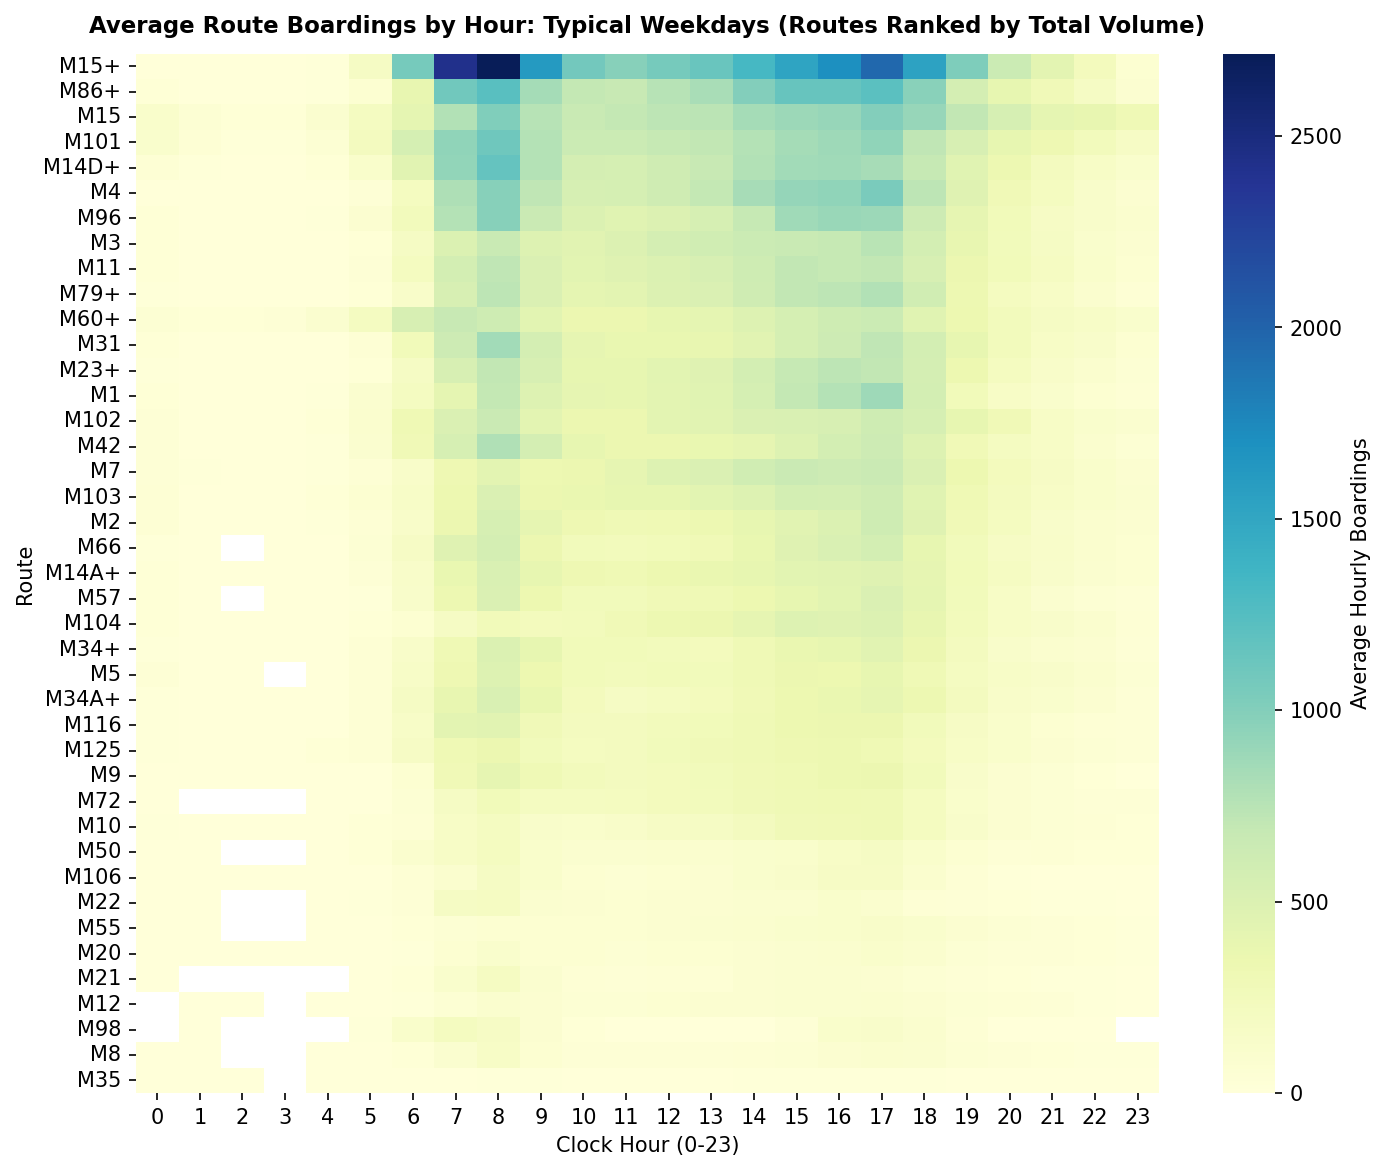

In [2]:
wd_typical = typical_days(matched, 'weekday')
route_order = wd_typical.groupby('route')['ridership'].sum().sort_values(ascending=False).index.tolist()

num_days = wd_typical['date'].nunique()
pivot_vol = wd_typical.pivot_table(index='route', columns='hour', values='ridership', aggfunc='sum') / num_days
pivot_vol = pivot_vol.reindex(index=route_order)

fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
sns.heatmap(pivot_vol, cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Average Hourly Boardings'})
ax.set_title('Average Route Boardings by Hour: Typical Weekdays (Routes Ranked by Total Volume)', fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Clock Hour (0-23)', fontsize=10)
ax.set_ylabel('Route', fontsize=10)
fig.savefig(FIG / 'm2_heatmap_riders_weekday.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 4.2: Riders per Trip Heatmaps (Blanked where Average Trips < 2/hr)
Blanking cells with fewer than 2 scheduled trips per hour filters out solitary late-night buses.

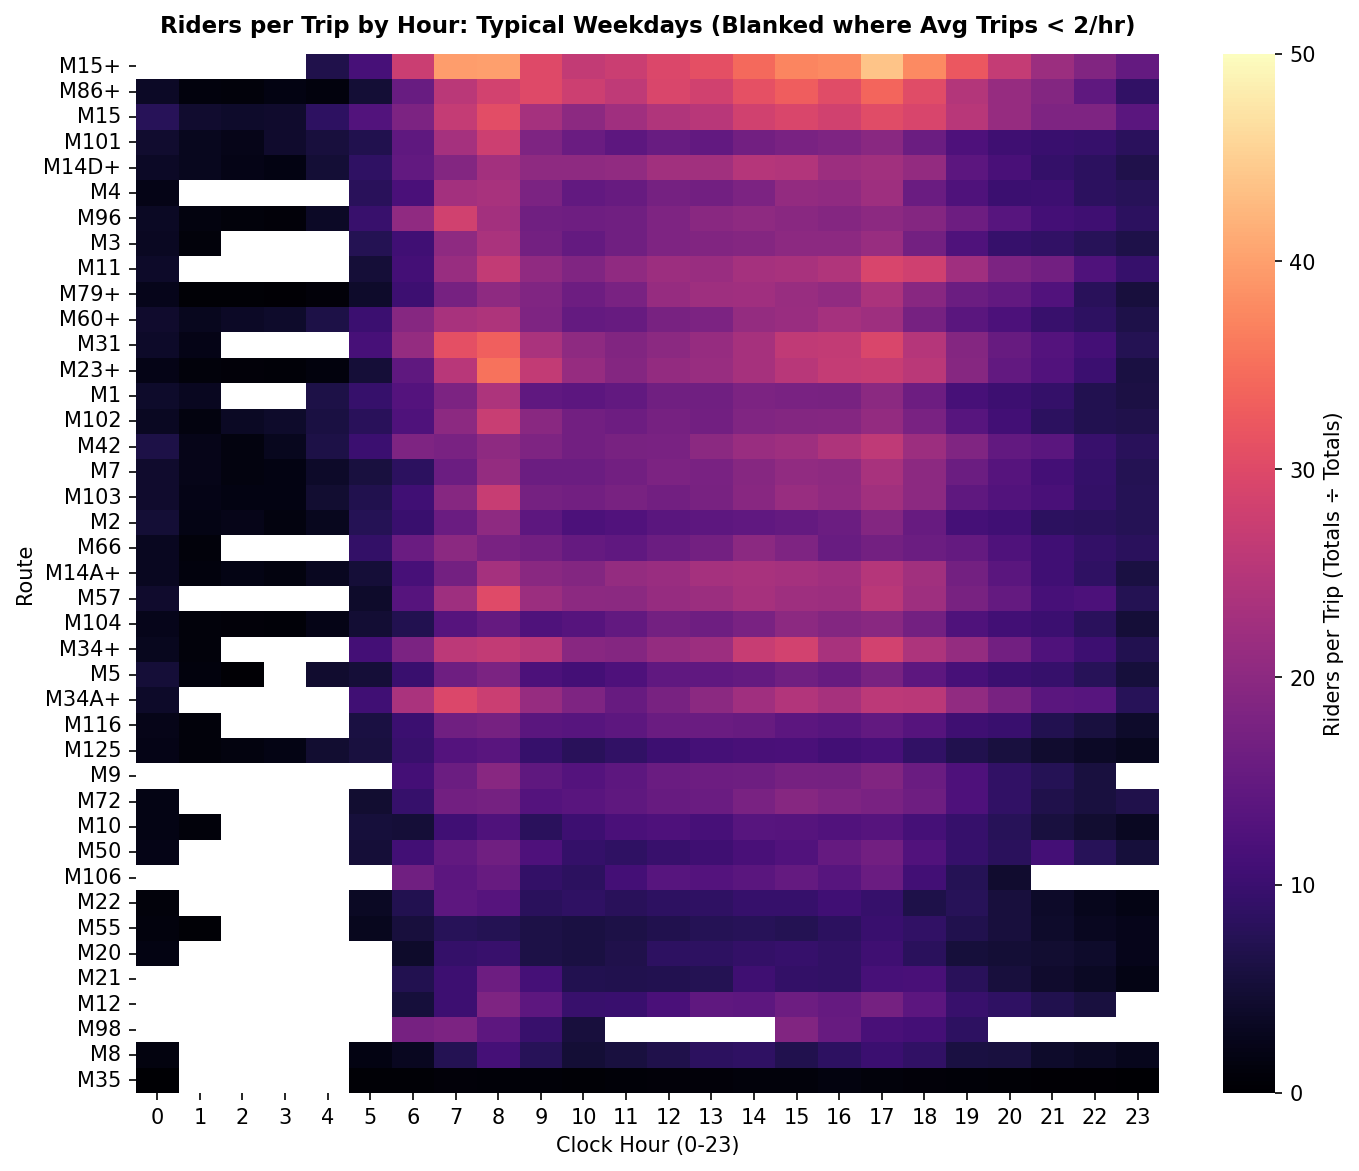

In [3]:
sum_riders = wd_typical.pivot_table(index='route', columns='hour', values='ridership', aggfunc='sum')
sum_trips = wd_typical.pivot_table(index='route', columns='hour', values='trips_running', aggfunc='sum')
avg_trips = sum_trips / num_days

# Divide totals by totals
with np.errstate(divide='ignore', invalid='ignore'):
    rpt_grid = np.where(sum_trips > 0, sum_riders / sum_trips, np.nan)
    # Blank out cells where avg_trips < 2.0
    rpt_filtered = np.where(avg_trips >= 2.0, rpt_grid, np.nan)

rpt_df = pd.DataFrame(rpt_filtered, index=sum_riders.index, columns=sum_riders.columns).reindex(index=route_order)

fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
sns.heatmap(rpt_df, cmap='magma', ax=ax, vmin=0, vmax=50, cbar_kws={'label': 'Riders per Trip (Totals ÷ Totals)'})
ax.set_title('Riders per Trip by Hour: Typical Weekdays (Blanked where Avg Trips < 2/hr)', fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Clock Hour (0-23)', fontsize=10)
ax.set_ylabel('Route', fontsize=10)
fig.savefig(FIG / 'm2_heatmap_rpt_weekday.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 4.3: Route Efficiency Summary Table
Evaluates riders per trip and riders per service-hour across 4 time bands (morning peak, midday, evening peak, night).

In [4]:
route_table = pd.read_csv(TAB / 'm2_route_performance_table.csv')
print(f'Total route-band performance entries: {len(route_table)}')
print('\nSample entries (Typical Weekday Peak and Off-Peak Performance):')
route_table[route_table['day_type'] == 'Typical Weekday'].head(15)

Total route-band performance entries: 492

Sample entries (Typical Weekday Peak and Off-Peak Performance):


,route,day_type,time_band,days_count,total_riders,total_trips,total_service_hours,riders_per_trip,riders_per_service_hour
0,M1,Typical Weekday,morning_peak,180,285869,15300,9081.02,18.68,31.48
1,M1,Typical Weekday,midday,180,529923,32400,20370.02,16.36,26.01
2,M1,Typical Weekday,evening_peak,180,399049,22320,13964.99,17.88,28.57
3,M1,Typical Weekday,night,180,124047,13693,7168.96,9.06,17.30
4,M10,Typical Weekday,morning_peak,180,90234,8640,4028.99,10.44,22.40
5,M10,Typical Weekday,midday,180,201872,16560,7995.02,12.19,25.25
6,M10,Typical Weekday,evening_peak,180,145978,11700,5958.00,12.48,24.50
7,M10,Typical Weekday,night,180,65963,12120,5318.28,5.44,12.40
8,M101,Typical Weekday,morning_peak,180,506464,22140,14106.01,22.88,35.90
9,M101,Typical Weekday,midday,180,772973,48960,32616.00,15.79,23.70


## Step 5: Demand Stability Across Typical Weekdays
Measures how much ridership varies from one weekday to the next using Coefficient of Variation ($CV = \sigma / \mu$).

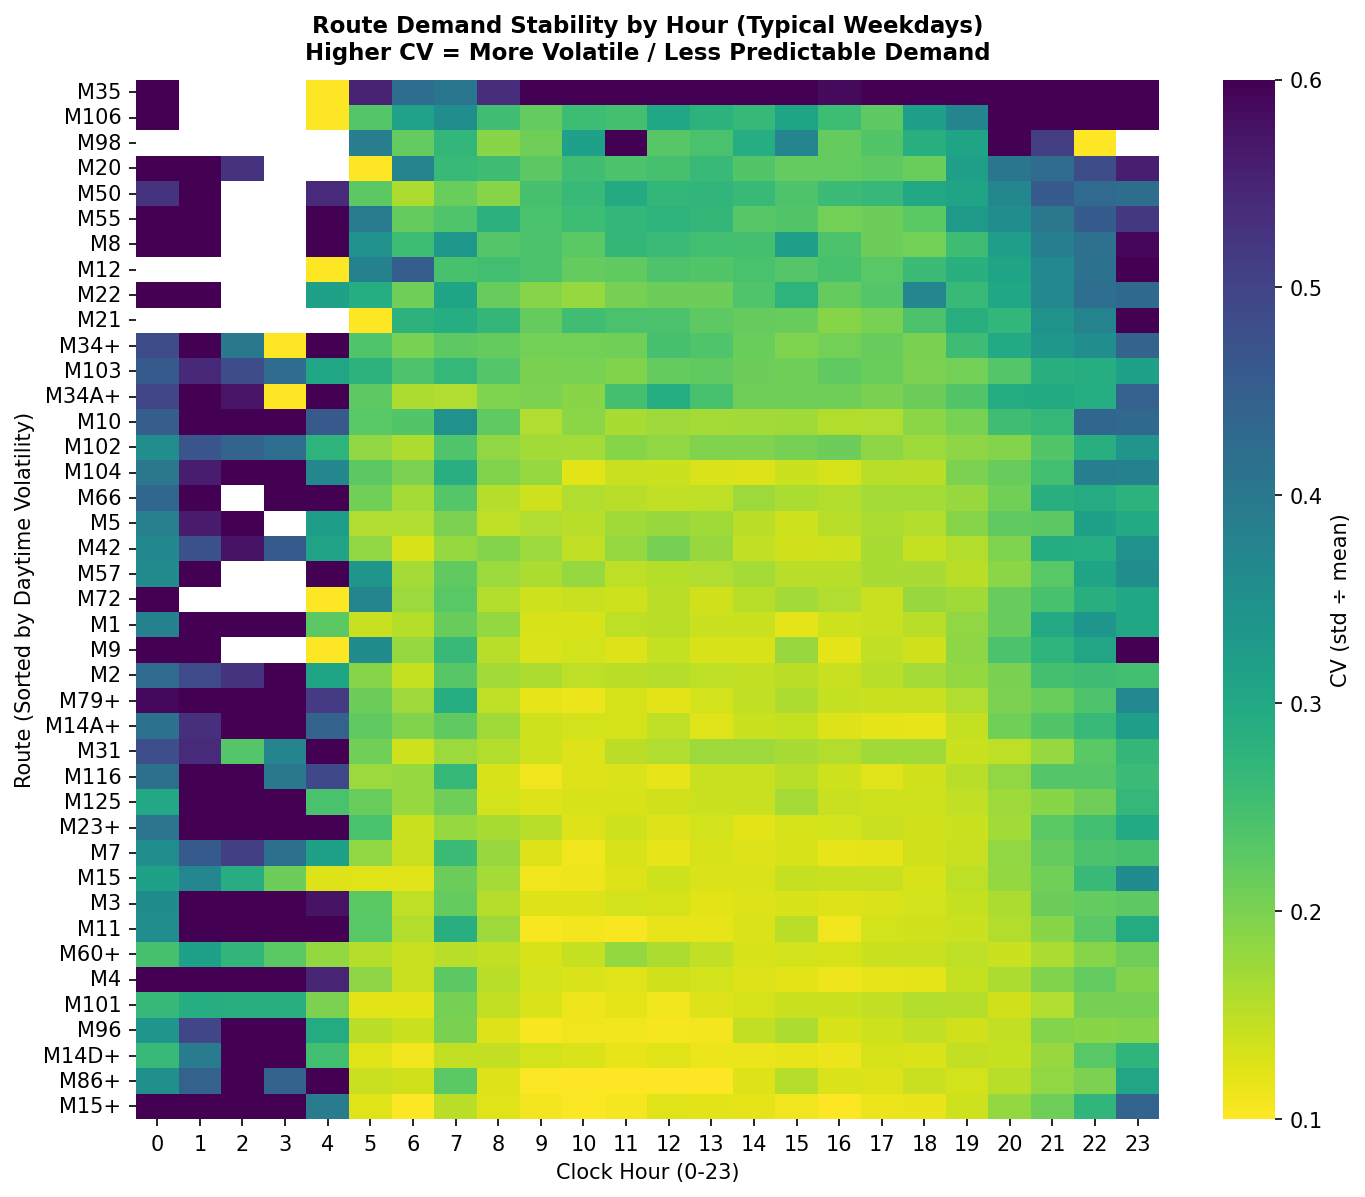

Top 5 Most Predictable Routes (Lowest CV):
route
M101     0.144
M96      0.141
M14D+    0.137
M86+     0.136
M15+     0.136
Name: cv, dtype: float64

Top 5 Most Volatile Routes (Highest CV):
route
M35     0.847
M106    0.468
M98     0.378
M20     0.287
M50     0.283
Name: cv, dtype: float64


In [5]:
var_table = pd.read_csv(TAB / 'm2_route_demand_variability.csv')
cv_pivot = var_table.pivot(index='route', columns='hour', values='cv')

# Rank routes by mean daytime CV (06:00 to 22:00)
daytime_cv = var_table[var_table['hour'].between(6, 22)].groupby('route')['cv'].mean().sort_values(ascending=False)
cv_pivot = cv_pivot.reindex(index=daytime_cv.index)

fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
sns.heatmap(cv_pivot, cmap='viridis_r', ax=ax, vmin=0.1, vmax=0.6, cbar_kws={'label': 'CV (std ÷ mean)'})
ax.set_title('Route Demand Stability by Hour (Typical Weekdays)\nHigher CV = More Volatile / Less Predictable Demand', fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Clock Hour (0-23)', fontsize=10)
ax.set_ylabel('Route (Sorted by Daytime Volatility)', fontsize=10)
fig.savefig(FIG / 'm2_demand_variability.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 5 Most Predictable Routes (Lowest CV):')
print(daytime_cv.tail(5).round(3))
print('\nTop 5 Most Volatile Routes (Highest CV):')
print(daytime_cv.head(5).round(3))